In [1]:
from typing import Annotated, TypedDict, Literal, List
from langgraph.graph import StateGraph, START, END
from langgraph.graph.message import add_messages, MessagesState
from langgraph.checkpoint.memory import InMemorySaver
from langgraph.types import Command, CachePolicy, interrupt, Send
from langgraph.runtime import Runtime
from langgraph.types import RetryPolicy, TimeoutPolicy
from langgraph.errors import NodeError
from langchain_core.messages import (
    BaseMessage, SystemMessage, HumanMessage, ToolMessage
)
from langchain.chat_models import init_chat_model
from langchain.tools import tool
from IPython.display import Image, display
from operator import add
from dotenv import load_dotenv
from pydantic.dataclasses import dataclass
from pydantic import BaseModel, Field

load_dotenv()

def display_graph(graph, xray=False):
    """显示图结构，xray=True 可展开子图内部结构"""
    display(Image(graph.get_graph(xray=xray).draw_mermaid_png()))
    
llm = init_chat_model("deepseek-chat")

In [ ]:
#顺序执行、并行执行、路由执行、Orchestrator-Worker+Send API、Evaluator-Opomizer(评估-优化循环)、子图嵌套

weather and 天气是晴朗,25度。
chat and 你好！很高兴见到你，有什么可以帮你的吗？
translate and I want to eat a hamburger.


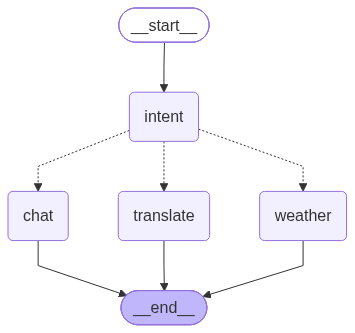

: 

In [ ]:
#路由模式会让模型根据用户问题做意图识别，然后分配任务到具体的工作节点

# 例如：写三个工作节点：
# - 天气节点：可以查询天气
# - 新闻节点：可以查询新闻
# - 翻译节点：可以翻译

# Start--意图识别节点--闲聊节点--（天气节点、新闻节点、翻译节点）--End

from typing import Literal, TypedDict

from langchain.chat_models import init_chat_model
from langchain_core.messages import HumanMessage, AIMessage
from langgraph.graph import StateGraph, START, END, MessagesState
from pydantic import BaseModel, Field
from langchain_core.messages import BaseMessage, HumanMessage, AIMessage
from langgraph.graph import StateGraph, MessagesState
from langgraph.checkpoint.memory import InMemorySaver
from typing import Annotated, Literal
from IPython.display import Image, display

# ===============Step 1: 初始化chat模型===============
llm = init_chat_model(
    'deepseek-flash',
    extra_body={'thinking': {'type': 'disabled'}}
)

# ===============Step 2: 定义State，记录用户输入、最终结果===============
class IntentState(MessagesState):
    intent: str #意图识别
    #messages: Annotated[list[BaseMessage], add_messages]

# ===============Step 4: 定义Node===============
def intent_node(state: IntentState):
    intent = llm.invoke(f'''
    根据用户的请求判断用户意图，可选意图：weather、translate或chat。
    user_query: {state['messages'][-1].content}
    ''')
    return {"intent": intent.content}

def chat_node(state: IntentState):
    res = llm.invoke(state['messages'])
    return {"messages": [res]}

def weather_node(state: IntentState):
    return {"messages": [AIMessage(content="天气是晴朗,25度。")]}

def translate_node(state: IntentState):
    res = llm.invoke(f'''
    按照用户要求翻译，只输出翻译结果，不要任何解释。
    user_query:{state['messages'][-1].content}
    ''')
    return {"messages": [res]}

def intent_router_node(state: IntentState) -> Literal["weather", "translate", "chat"]:
    """根据意图识别到不同处理器"""
    return state["intent"]


graph = StateGraph(IntentState)
graph.add_node("intent", intent_node)
graph.add_node("chat", chat_node)
graph.add_node("weather", weather_node)
graph.add_node("translate", translate_node)

graph.add_edge(START, "intent")
graph.add_conditional_edges("intent", intent_router_node)
graph.add_edge("weather", END)
graph.add_edge("translate", END)
graph.add_edge("chat", END)

builder = graph.compile()

for s in ["今天天气怎么样", "你好", "翻译下我想吃汉堡"]:
    res = builder.invoke({"messages": [HumanMessage(content=s)]})
    print(f"{res["intent"]} and {res["messages"][-1].content}")

Image(builder.get_graph(xray=True).draw_mermaid_png())
